In [5]:
#TEJAS RAJ
#1VE23CD057

import numpy as np
import matplotlib.pyplot as plt
import torch
import torch.nn as nn

torch.manual_seed(42)
np.random.seed(42)

device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

print("Using device:", device)

Using device: cpu


In [13]:
class PINN(nn.Module):
    def __init__(self):
        super().__init__()

        self.network = nn.Sequential(
            nn.Linear(2, 32),
            nn.Tanh(),
            nn.Linear(32, 32),
            nn.Tanh(),
            nn.Linear(32, 32),
            nn.Tanh(),
            nn.Linear(32, 1)
        )

    def forward(self, x, t):
        inputs = torch.cat([x, t], dim=1)
        return self.network(inputs)


model = PINN().to(device)

optimizer = torch.optim.Adam(
    model.parameters(), lr=0.001
)

alpha = 0.1

print(model)

PINN(
  (network): Sequential(
    (0): Linear(in_features=2, out_features=32, bias=True)
    (1): Tanh()
    (2): Linear(in_features=32, out_features=32, bias=True)
    (3): Tanh()
    (4): Linear(in_features=32, out_features=32, bias=True)
    (5): Tanh()
    (6): Linear(in_features=32, out_features=1, bias=True)
  )
)


In [7]:
# Points inside the space-time domain
N_f = 2000

x_f = torch.rand(N_f, 1, device=device)
t_f = torch.rand(N_f, 1, device=device)

x_f.requires_grad_(True)
t_f.requires_grad_(True)

# Initial condition: T(x, 0) = sin(pi*x)
N_i = 200

x_i = torch.rand(N_i, 1, device=device)
t_i = torch.zeros_like(x_i)

T_i = torch.sin(np.pi * x_i)

# Boundary conditions: T(0,t) = T(1,t) = 0
N_b = 200

t_b = torch.rand(N_b, 1, device=device)

x_left = torch.zeros_like(t_b)
x_right = torch.ones_like(t_b)

print("Physics points:", N_f)
print("Initial points:", N_i)
print("Boundary points:", 2 * N_b)

Physics points: 2000
Initial points: 200
Boundary points: 400


In [12]:
def pinn_loss():
    # Predict temperature inside the domain
    T_f = model(x_f, t_f)

    # First derivatives
    T_t = torch.autograd.grad(
        T_f, t_f,
        grad_outputs=torch.ones_like(T_f),
        create_graph=True
    )[0]

    T_x = torch.autograd.grad(
        T_f, x_f,
        grad_outputs=torch.ones_like(T_f),
        create_graph=True
    )[0]

    # Second derivative with respect to position
    T_xx = torch.autograd.grad(
        T_x, x_f,
        grad_outputs=torch.ones_like(T_x),
        create_graph=True
    )[0]

    # Heat equation residual
    residual = T_t - alpha * T_xx

    loss_physics = torch.mean(residual**2)

    # Initial condition loss
    T_initial_pred = model(x_i, t_i)

    loss_initial = torch.mean(
        (T_initial_pred - T_i)**2
    )

    # Boundary condition losses
    T_left = model(x_left, t_b)
    T_right = model(x_right, t_b)

    loss_boundary = (
        torch.mean(T_left**2)
        + torch.mean(T_right**2)
    )

    # Total PINN loss
    total_loss = (
        loss_physics
        + loss_initial
        + loss_boundary
    )

    return (
        total_loss,
        loss_physics,
        loss_initial,
        loss_boundary
    )

In [14]:
epochs = 3000
loss_history = []

for epoch in range(epochs):

    optimizer.zero_grad()

    total, physics, initial, boundary = pinn_loss()

    total.backward()
    optimizer.step()

    loss_history.append(total.item())

    if (epoch + 1) % 500 == 0:
        print(
            f"Epoch {epoch + 1:4d} | "
            f"Total Loss: {total.item():.6e} | "
            f"Physics: {physics.item():.6e} | "
            f"Initial: {initial.item():.6e} | "
            f"Boundary: {boundary.item():.6e}"
        )

Epoch  500 | Total Loss: 3.839339e-03 | Physics: 2.447478e-03 | Initial: 7.419115e-04 | Boundary: 6.499499e-04
Epoch 1000 | Total Loss: 8.311786e-04 | Physics: 6.228983e-04 | Initial: 1.067070e-04 | Boundary: 1.015733e-04
Epoch 1500 | Total Loss: 2.154891e-04 | Physics: 1.759242e-04 | Initial: 1.638058e-05 | Boundary: 2.318432e-05
Epoch 2000 | Total Loss: 9.042507e-05 | Physics: 7.651905e-05 | Initial: 3.365323e-06 | Boundary: 1.054070e-05
Epoch 2500 | Total Loss: 6.686190e-05 | Physics: 5.798458e-05 | Initial: 1.445360e-06 | Boundary: 7.431957e-06
Epoch 3000 | Total Loss: 8.062868e-05 | Physics: 5.180035e-05 | Initial: 6.997958e-06 | Boundary: 2.183037e-05


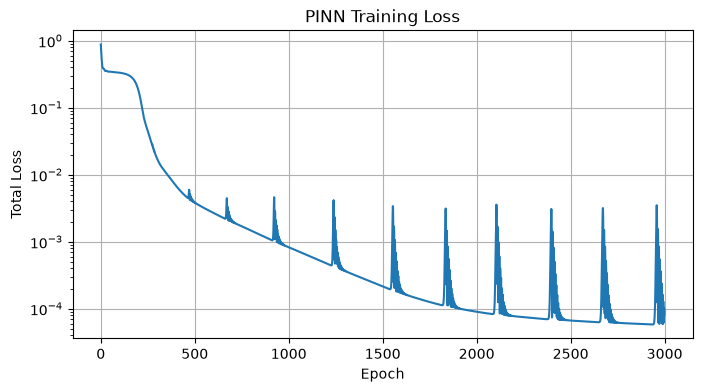

In [15]:
plt.figure(figsize=(8, 4))

plt.plot(loss_history)

plt.xlabel("Epoch")
plt.ylabel("Total Loss")
plt.title("PINN Training Loss")
plt.yscale("log")
plt.grid(True)

plt.show()